task 3 :clustering analysis(k-means)

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df=pd.read_csv("cleaned_iris_dataset.csv")
display(df)

#standardisation
x=df.drop(columns="species")
x_scaled= StandardScaler().fit_transform(x)
display(x_scaled)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
142,6.7,3.0,5.2,2.3,virginica
143,6.3,2.5,5.0,1.9,virginica
144,6.5,3.0,5.2,2.0,virginica
145,6.2,3.4,5.4,2.3,virginica


array([[-0.91550949,  1.0199714 , -1.35773692, -1.33570001],
       [-1.15755966, -0.12808217, -1.35773692, -1.33570001],
       [-1.39960983,  0.33113926, -1.41477817, -1.33570001],
       [-1.52063491,  0.10152855, -1.30069567, -1.33570001],
       [-1.03653457,  1.24958212, -1.35773692, -1.33570001],
       [-0.55243423,  1.93841426, -1.18661318, -1.07090176],
       [-1.52063491,  0.79036069, -1.35773692, -1.20330089],
       [-1.03653457,  0.79036069, -1.30069567, -1.33570001],
       [-1.76268509, -0.35769288, -1.35773692, -1.33570001],
       [-1.15755966,  0.10152855, -1.30069567, -1.46809914],
       [-0.55243423,  1.47919283, -1.30069567, -1.33570001],
       [-1.27858474,  0.79036069, -1.24365442, -1.33570001],
       [-1.27858474, -0.12808217, -1.35773692, -1.46809914],
       [-1.88371017, -0.12808217, -1.52886066, -1.46809914],
       [-0.06833389,  2.16802498, -1.47181942, -1.33570001],
       [-0.18935898,  3.08646783, -1.30069567, -1.07090176],
       [-0.55243423,  1.

K-Means uses distances between point and features with larger scales would dominate the distance.
StandardScaler gives each feature a mean of 0 and a standard deviation of 1 ,this way, all features contribute equally

[588.0, 220.85907940742362, 138.25771133117863, 112.90751031641204, 89.87757383602029, 79.72712144168358, 69.97548578558283, 61.97952195675171, 53.830749554034746, 47.13219214850164]


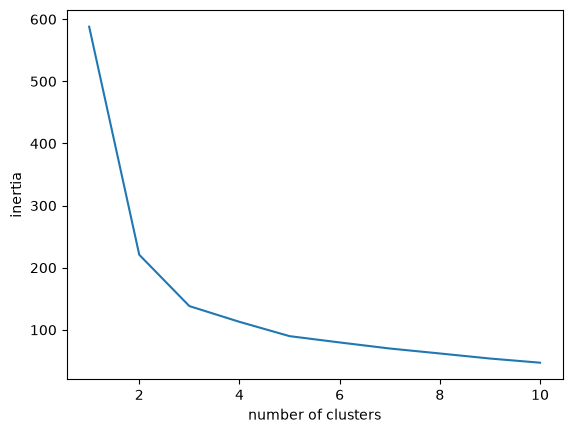

In [ ]:
inertia=[]
for k in range(1,11):
    inertia.append(KMeans(n_clusters=k,n_init=10).fit(x_scaled).inertia_)
print(inertia)

#basic visualisation
plt.plot(range(1,11),inertia)
plt.xlabel("number of clusters")
plt.ylabel("inertia")
plt.show()



The inertia drops sharply from k = 1 to k = 3.
After k = 3, the curve flattens so the elbow is at k = 3

In [ ]:
#the optimal number of cluster is 3(elbow method)
k=3
#adding the clusters column
df["cluster"]=KMeans(n_clusters=k).fit_predict(x_scaled)

display(df)

,sepal_length,sepal_width,petal_length,petal_width,species,cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1
...,...,...,...,...,...,...
142,6.7,3.0,5.2,2.3,virginica,0
143,6.3,2.5,5.0,1.9,virginica,2
144,6.5,3.0,5.2,2.0,virginica,0
145,6.2,3.4,5.4,2.3,virginica,0


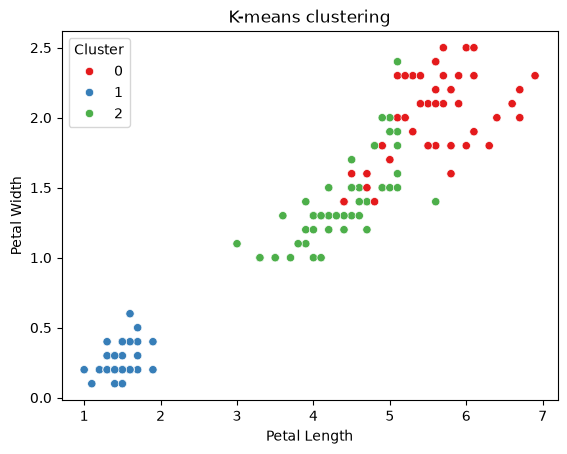

cluster      0   1   2
species               
setosa       0  48   0
versicolor  11   0  39
virginica   36   0  13


In [ ]:
#2D visualisation

import seaborn as sns

sns.scatterplot(data=df,x="petal_length", y="petal_width", hue="cluster", palette="Set1")
plt.title("K-means clustering")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend(title="Cluster")
plt.show()

print(pd.crosstab(df["species"],df["cluster"]))